# Paso 1: Configuración del entorno y división estratificada

In [1]:
import os
import joblib
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, RobustScaler, MinMaxScaler, OrdinalEncoder, OneHotEncoder

# 1. Carga del dataset crudo
ruta_csv = 'clientes_banca_raw.csv'
df_raw = pd.read_csv(ruta_csv)

# 2. Separación de características predictoras (X) y variable objetivo (y)
X = df_raw.drop(columns=['abandono'])
y = df_raw['abandono']

# 3. Partición Train / Test estratificada (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Dimensiones de X_train inicial: {X_train.shape}")
print(f"Dimensiones de X_test inicial:  {X_test.shape}")

Dimensiones de X_train inicial: (480, 14)
Dimensiones de X_test inicial:  (120, 14)


# Paso 2: Función para el tratamiento inicial de los datos

## Ejercicio A

In [2]:
def _descartar_columnas_no_utilizables(df: pd.DataFrame) -> pd.DataFrame:
    # Quitar identificadores y columnas que dan pistas falsas o tienen demasiados nulos
    columnas_descarte = ['id_cliente', 'salario_mensual_aprox', 'comentarios_cliente', 'motivo_cancelacion']
    return df.drop(columns=columnas_descarte, errors='ignore')

def _sanitizar_centinelas_numericos(df: pd.DataFrame) -> pd.DataFrame:
    # Cambiar números imposibles o códigos raros por valores vacíos
    if 'edad' in df.columns:
        df.loc[(df['edad'] <= 0) | (df['edad'] > 120), 'edad'] = np.nan
    if 'ingresos_anuales' in df.columns:
        df.loc[df['ingresos_anuales'] <= 0, 'ingresos_anuales'] = np.nan
    if 'saldo_cuenta' in df.columns:
        df['saldo_cuenta'] = df['saldo_cuenta'].replace(-999, np.nan)
    return df

def _sanitizar_categoricos(df: pd.DataFrame) -> pd.DataFrame:
    # Limpiar espacios sobrantes, ponemos mayúsculas iniciales y quitamos signos de interrogación
    if 'tipo_cuenta' in df.columns:
        df['tipo_cuenta'] = df['tipo_cuenta'].astype(str).str.strip().str.capitalize()
        df['tipo_cuenta'] = df['tipo_cuenta'].replace({'Desconocido': np.nan, '?': np.nan, 'Nan': np.nan})

    if 'canal_preferido' in df.columns:
        df['canal_preferido'] = df['canal_preferido'].astype(str).str.strip()
        df['canal_preferido'] = df['canal_preferido'].replace({'???': np.nan, 'Nan': np.nan})

    if 'nivel_estudios' in df.columns:
        df['nivel_estudios'] = df['nivel_estudios'].astype(str).str.strip().replace({'Nan': np.nan, 'nan': np.nan})
    return df

def _feature_engineering(df: pd.DataFrame) -> pd.DataFrame:
    # Crear las nuevas columnas que nos dan pistas útiles para el negocio
    if 'saldo_cuenta' in df.columns and 'ingresos_anuales' in df.columns:
        df['ratio_saldo_ingresos'] = df['saldo_cuenta'] / (df['ingresos_anuales'] + 1)

    if 'saldo_cuenta' in df.columns and 'num_productos' in df.columns:
        df['saldo_por_producto'] = df['saldo_cuenta'] / df['num_productos']

    if 'edad' in df.columns:
        limites_edad = [0, 30, 55, 120]
        etiquetas_edad = ['Joven', 'Adulto', 'Senior']
        df['grupo_edad'] = pd.cut(df['edad'], bins=limites_edad, labels=etiquetas_edad).astype(str)

    if 'antiguedad_meses' in df.columns:
        df['antiguedad_anios'] = df['antiguedad_meses'] / 12.0
        df = df.drop(columns=['antiguedad_meses'])
    return df

def preparar_datos_crudos(df_entrada: pd.DataFrame) -> pd.DataFrame:
    # Función principal
    df = df_entrada.copy()
    df = _descartar_columnas_no_utilizables(df)
    df = _sanitizar_centinelas_numericos(df)
    df = _sanitizar_categoricos(df)
    df = _feature_engineering(df)
    return df

Verificar columnas resultantes

In [3]:
X_train_prep = preparar_datos_crudos(X_train)
X_test_prep = preparar_datos_crudos(X_test)

print(f"Columnas resultantes tras la preparación ({len(X_train_prep.columns)}):")
print(list(X_train_prep.columns))
X_train_prep.head(3)

Columnas resultantes tras la preparación (13):
['edad', 'ingresos_anuales', 'saldo_cuenta', 'nivel_estudios', 'tipo_cuenta', 'nivel_satisfaccion', 'num_productos', 'tiene_tarjeta', 'canal_preferido', 'ratio_saldo_ingresos', 'saldo_por_producto', 'grupo_edad', 'antiguedad_anios']


,edad,ingresos_anuales,saldo_cuenta,nivel_estudios,tipo_cuenta,nivel_satisfaccion,num_productos,tiene_tarjeta,canal_preferido,ratio_saldo_ingresos,saldo_por_producto,grupo_edad,antiguedad_anios
581,65.0,43522.31,5780.88,Grado,Corriente,Medio,1,1,App Movil,0.132823,5780.880,Senior,8.333333
462,40.0,34205.72,14225.97,Secundaria,Corriente,Bajo,2,1,App Movil,0.415882,7112.985,Adulto,9.500000
381,32.0,14066.62,0.00,Secundaria,Corriente,Muy Alto,2,1,Web,0.000000,0.000,Adulto,5.250000


## Ejercicio B

In [4]:
# 1. Comprobar que se han eliminado columnas inutilizables
print(X_train_prep.columns)

# 2. Comprobar que se han añadido las columnas de feature engineering
print("\n")
print(X_train_prep.columns)

# 3. Valores únicos de tipo_cuenta y comprobación de nulos
print("\nValores únicos de tipo_cuenta:")
print(X_train_prep['tipo_cuenta'].unique())

print("\nNulos en tipo_cuenta:")
print(X_train_prep['tipo_cuenta'].isna().sum())

Index(['edad', 'ingresos_anuales', 'saldo_cuenta', 'nivel_estudios',
       'tipo_cuenta', 'nivel_satisfaccion', 'num_productos', 'tiene_tarjeta',
       'canal_preferido', 'ratio_saldo_ingresos', 'saldo_por_producto',
       'grupo_edad', 'antiguedad_anios'],
      dtype='str')


Index(['edad', 'ingresos_anuales', 'saldo_cuenta', 'nivel_estudios',
       'tipo_cuenta', 'nivel_satisfaccion', 'num_productos', 'tiene_tarjeta',
       'canal_preferido', 'ratio_saldo_ingresos', 'saldo_por_producto',
       'grupo_edad', 'antiguedad_anios'],
      dtype='str')

Valores únicos de tipo_cuenta:
<StringArray>
['Corriente', 'Ahorro', 'Nomina', 'Inversion', nan]
Length: 5, dtype: str

Nulos en tipo_cuenta:
1


# Paso 3: Función de construcción del ColumnTransformer

In [5]:
def construir_pipeline_preprocesamiento() -> ColumnTransformer:
    # 1. Columnas numéricas sin atípicos
    cols_num_standard = ['edad', 'num_productos', 'antiguedad_anios']

    # 2. Columnas numéricas con valores atípicos o asimétricas
    cols_num_robust = [
        'ingresos_anuales',
        'saldo_cuenta',
        'ratio_saldo_ingresos',
        'saldo_por_producto'
    ]

    cols_ordinales = ['nivel_estudios', 'nivel_satisfaccion']
    cols_nominales = ['tipo_cuenta', 'canal_preferido', 'grupo_edad']
    cols_passthrough = ['tiene_tarjeta']

    # Sub-pipeline 1: Numérico Estándar (media + StandardScaler)
    pipeline_num_std = Pipeline([
        ('imputador', SimpleImputer(strategy='mean')),
        ('escalador', StandardScaler())
    ])

    # Sub-pipeline 2: Numérico Robusto (mediana + RobustScaler)
    pipeline_num_rob = Pipeline([
        ('imputador', SimpleImputer(strategy='median')),
        ('escalador', RobustScaler())
    ])

    # Sub-pipeline 3: Categórico Ordinal (moda + OrdinalEncoder + MinMaxScaler)
    orden_estudios = ['Primaria', 'Secundaria', 'Grado', 'Master', 'Doctorado']
    orden_satisfaccion = ['Muy Bajo', 'Bajo', 'Medio', 'Alto', 'Muy Alto']

    pipeline_ord = Pipeline([
        ('imputador', SimpleImputer(strategy='most_frequent')),
        ('codificador', OrdinalEncoder(categories=[orden_estudios, orden_satisfaccion])),
        ('escalador', MinMaxScaler())
    ])

    # Sub-pipeline 4: Categórico Nominal (moda + OneHotEncoder)
    pipeline_nom = Pipeline([
        ('imputador', SimpleImputer(strategy='most_frequent')),
        ('codificador', OneHotEncoder(sparse_output=False, handle_unknown='ignore'))
    ])

    # Ensamble de ramas en ColumnTransformer
    preprocesador = ColumnTransformer(
        transformers=[
            ('num_std', pipeline_num_std, cols_num_standard),
            ('num_rob', pipeline_num_rob, cols_num_robust),
            ('ord', pipeline_ord, cols_ordinales),
            ('nom', pipeline_nom, cols_nominales),
            ('bool', 'passthrough', cols_passthrough)
        ],
        remainder='drop'
    )

    # Configuramos la salida para que devuelva directamente DataFrames de Pandas
    preprocesador.set_output(transform='pandas')

    return preprocesador

Revisar arquitectura

In [6]:
preprocesador = construir_pipeline_preprocesamiento()
preprocesador

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num_std', ...), ('num_rob', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``f

## Ejercicio A

Sirve para que el sistema no dé error si un cliente escribe una opción que no había en los datos antiguos. Si alguien pone un tipo de cuenta diferente como Inversión, daría un error. Al poner ignore, le pone ceros en todas las columnas y sigue funcionando.

## Ejercicio B

La función devuelve la estructura del ColumnTransformer con todas sus ramas, pero está vacío. Aún no ha aprendido porque no se ha llegado a ejecutar fit.

## Ejercicio C

Porque la edad o los años están equilibradas, así que StandardScaler funciona bien con ellas. Pero en el saldo o los sueldos hay clientes con mucho dinero que desvían la media, así que se usa RobustScaler para que se fije en la mediana.

## Ejercicio D

Porque aunque en el archivo no hubiera huecos vacíos, en la vida real un cliente puede olvidarse de rellenar una casilla. Si no usara el imputador, al llegar un dato vacío el modelo daría error.

## Ejercicio E

Son columnas que no necesitan ningún cambio y que se dejan como vienen. Como puede ser tiene_tarjeta, porque ya es un valor con ceros y unos que el modelo entiende sin tener que transformarlo.

# Paso 4: Función de ajuste y serialización

In [7]:
def ajustar_y_guardar_preprocesador(
    preprocesador: ColumnTransformer,
    X_train_prep: pd.DataFrame,
    X_test_prep: pd.DataFrame,
    ruta_guardado: str = 'preprocesador_banca.joblib'
):
    print("--> Ajustando preprocesador sobre X_train (fit_transform)...")
    X_train_final = preprocesador.fit_transform(X_train_prep)

    print("--> Aplicando preprocesador sobre X_test (transform)...")
    X_test_final = preprocesador.transform(X_test_prep)

    print(f"Dimensiones de X_train_final: {X_train_final.shape}")
    print(f"Dimensiones de X_test_final:  {X_test_final.shape}")

    # Guardamos el artefacto entrenado
    joblib.dump(preprocesador, ruta_guardado)
    print(f"✅ Preprocesador exportado con éxito en: {ruta_guardado}")

    return X_train_final, X_test_final

In [8]:
X_train_final, X_test_final = ajustar_y_guardar_preprocesador(
    preprocesador, X_train_prep, X_test_prep
)

X_train_final.head()

--> Ajustando preprocesador sobre X_train (fit_transform)...
--> Aplicando preprocesador sobre X_test (transform)...
Dimensiones de X_train_final: (480, 22)
Dimensiones de X_test_final:  (120, 22)
✅ Preprocesador exportado con éxito en: preprocesador_banca.joblib


,num_std__edad,num_std__num_productos,num_std__antiguedad_anios,num_rob__ingresos_anuales,num_rob__saldo_cuenta,num_rob__ratio_saldo_ingresos,num_rob__saldo_por_producto,ord__nivel_estudios,ord__nivel_satisfaccion,nom__tipo_cuenta_Ahorro,...,nom__tipo_cuenta_Nomina,nom__canal_preferido_App Movil,nom__canal_preferido_Cajero Antiguo,nom__canal_preferido_Oficina,nom__canal_preferido_Telefono,nom__canal_preferido_Web,nom__grupo_edad_Adulto,nom__grupo_edad_Joven,nom__grupo_edad_Senior,bool__tiene_tarjeta
581,1.920455,-1.013608,1.142876,0.982371,-0.029182,-0.168256,0.212178,0.50,0.50,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1
462,-0.192548,0.181802,1.566423,0.433318,0.551872,0.339799,0.360952,0.25,0.25,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1
381,-0.868709,0.181802,0.023502,-0.753538,-0.426929,-0.406655,-0.433449,0.25,1.00,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1
549,-0.446108,-1.013608,-0.369791,-0.128570,-0.049532,-0.007623,0.179146,0.00,0.25,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1
128,1.328814,1.377212,-0.127765,0.329618,2.082159,1.610596,0.924145,0.50,0.50,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0


## Ejercicio A

Fit_transform primero aprende las reglas de los datos y luego los transforma, mientras que transform solo aplica esas reglas ya aprendidas. No se tiene que hacer fit en test porque estaríamos utilizando información de esos datos para aprender, cuando el preprocesador tiene que aprender del train.

## Ejercicio B

In [9]:
# Comprobación de que no queda ningún nulo
print("Nulos totales en X_train_final:", X_train_final.isna().sum().sum())
print("Nulos totales en X_test_final:", X_test_final.isna().sum().sum())

Nulos totales en X_train_final: 0
Nulos totales en X_test_final: 0


# Paso 5: Simulación de inferencia en producción

In [10]:
def transformar_cliente_nuevo(
    datos_cliente: dict,
    ruta_artefacto: str = 'preprocesador_banca.joblib'
) -> pd.DataFrame:
    # 1. Cargamos el artefacto preprocesador entrenado
    preprocesador_cargado = joblib.load(ruta_artefacto)

    # 2. Convertimos a DataFrame de 1 fila
    df_nuevo = pd.DataFrame([datos_cliente])

    # 3. Aplicamos la misma limpieza previa determinista
    df_nuevo_prep = preparar_datos_crudos(df_nuevo)

    # 4. Transformamos con el pipeline sin hacer fit
    df_salida = preprocesador_cargado.transform(df_nuevo_prep)

    return df_salida

Cliente simulado

In [11]:
cliente_simulado = {
    'id_cliente': 'CLI-9999',
    'edad': 42.0,
    'ingresos_anuales': 48000.0,
    'saldo_cuenta': 14200.0,
    'num_productos': 2,
    'tiene_tarjeta': 1,
    'antiguedad_meses': 60,
    'tipo_cuenta': '  ahorro  ',
    'canal_preferido': 'App Movil',
    'nivel_estudios': 'Grado',
    'nivel_satisfaccion': 'Alto'
}

df_cliente = transformar_cliente_nuevo(cliente_simulado)

print(f"Forma del DataFrame resultante: {df_cliente.shape}")
df_cliente

Forma del DataFrame resultante: (1, 22)


,num_std__edad,num_std__num_productos,num_std__antiguedad_anios,num_rob__ingresos_anuales,num_rob__saldo_cuenta,num_rob__ratio_saldo_ingresos,num_rob__saldo_por_producto,ord__nivel_estudios,ord__nivel_satisfaccion,nom__tipo_cuenta_Ahorro,...,nom__tipo_cuenta_Nomina,nom__canal_preferido_App Movil,nom__canal_preferido_Cajero Antiguo,nom__canal_preferido_Oficina,nom__canal_preferido_Telefono,nom__canal_preferido_Web,nom__grupo_edad_Adulto,nom__grupo_edad_Joven,nom__grupo_edad_Senior,bool__tiene_tarjeta
0,-0.023508,0.181802,-0.067258,1.246254,0.550085,0.124316,0.359502,0.5,0.75,1.0,...,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1


## Ejercicio A

Es simular lo que pasará en la aplicación cuando un usuario rellene el formulario: coger sus datos en bruto, limpiar los fallos y prepararlo en una sola fila lista para que el modelo le dé la predicción.

## Ejercicio B

Cuando el servidor recibe la petición y antes de usar el modelo. Primero tengo el formulario con los datos en bruto, le paso esta función para convertirlo en números para que lo entienda el modelo y con eso ya puedo saber si el cliente se va o se queda.

# Paso 6: Entrenamiento y exportación en el Notebook

Entrenamiento, inferencia y evaluación del modelo KNN

In [12]:
from sklearn.neighbors import KNeighborsClassifier

# 1. Instanciamos el clasificador KNN con 5 vecinos
knn = KNeighborsClassifier(n_neighbors=5)

# 2. Entrenamos el modelo con los datos procesados de entrenamiento
print("--> Entrenando modelo KNeighborsClassifier...")
knn.fit(X_train_final, y_train)
print("✅ Modelo entrenado con éxito.")

--> Entrenando modelo KNeighborsClassifier...
✅ Modelo entrenado con éxito.


In [13]:
# 1. Predicción de la etiqueta binaria (0: Permanece, 1: Abandona)
prediccion = knn.predict(df_cliente)

# 2. Estimación de probabilidades para cada clase [P(Permanece), P(Abandona)]
probabilidades = knn.predict_proba(df_cliente)

print(f"Predicción de clase: {prediccion[0]} ({'Abandona' if prediccion[0] == 1 else 'Permanece'})")
print(f"Vector de probabilidades: {probabilidades[0]}")
print(f"Probabilidad de que abandone el banco: {probabilidades[0][1]:.2%}")

Predicción de clase: 0 (Permanece)
Vector de probabilidades: [0.6 0.4]
Probabilidad de que abandone el banco: 40.00%


Exactitud global (Accuracy) en Test: 0.5667 (56.7%)



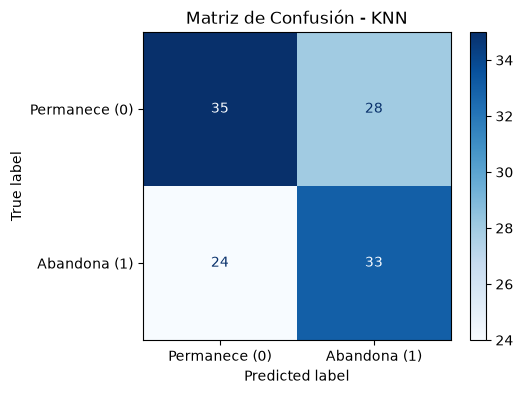

In [14]:
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

# 1. Predicciones para todo el conjunto de test
y_pred = knn.predict(X_test_final)

# 2. Tasa de acierto global (Accuracy)
acc = accuracy_score(y_test, y_pred)
print(f"Exactitud global (Accuracy) en Test: {acc:.4f} ({acc * 100:.1f}%)\n")

# 3. Representación gráfica de la Matriz de Confusión
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, 
    y_pred, 
    display_labels=['Permanece (0)', 'Abandona (1)'], 
    cmap='Blues', 
    ax=ax
)
plt.title('Matriz de Confusión - KNN')
plt.grid(False)
plt.show()

Exportación de los dos artefactos con joblib

In [15]:
import joblib
import os

# Creamos la carpeta de artefactos de la API si no existe
ruta_dir_artifacts = os.path.join('api_abandono_banca', 'artifacts')
os.makedirs(ruta_dir_artifacts, exist_ok=True)

# 1. Exportamos el preprocesador ajustado
ruta_preprocesador = os.path.join(ruta_dir_artifacts, 'preprocesador_banca.joblib')
joblib.dump(preprocesador, ruta_preprocesador)
print(f"✅ Preprocesador guardado en: {ruta_preprocesador}")

# 2. Exportamos el modelo KNN entrenado
ruta_modelo = os.path.join(ruta_dir_artifacts, 'modelo_knn.joblib')
joblib.dump(knn, ruta_modelo)
print(f"✅ Modelo guardado en: {ruta_modelo}")


✅ Preprocesador guardado en: api_abandono_banca\artifacts\preprocesador_banca.joblib
✅ Modelo guardado en: api_abandono_banca\artifacts\modelo_knn.joblib
